In [29]:
from langgraph.graph import StateGraph ,START,END
from typing import TypedDict,Literal
import os
from dotenv import load_dotenv
from google import genai
from pydantic import BaseModel, Field
from langchain_google_genai import ChatGoogleGenerativeAI

In [30]:
load_dotenv()
api_key = os.getenv("my_api_key")


In [31]:
model= ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite",google_api_key=api_key)

In [32]:
class SentimentSchema(BaseModel):
    sentiment: Literal["positive", "negative"] = Field(
        description="sentiment of the review"
    )

In [33]:
class DiagnosisSchema(BaseModel):
    issue_type: Literal["ux","performance","bug","support","other"]= Field(description='the catagory show issue mention on the review')
    tone: Literal["clam","frustated","angry","dissponted"]= Field(description='the catagory show thw tone of the user')
    urgency : Literal["low","high","medium"]= Field(description='this show user urgency')

In [34]:
structured_output=model.with_structured_output(SentimentSchema)
structured_output1= model.with_structured_output(DiagnosisSchema)

In [35]:
# prompt = 'What is the sentiment of the following review - The software too baaaad'
# structured_op1.invoke(prompt).sentiment

In [36]:
class ReviewState(TypedDict):
    review: str
    sentiment: Literal["positive", "negative"]
    diagnosis: dict
    response: str


In [37]:
def find_sentiment(state: ReviewState):
    prompt = f'For the following review find out the sentiment:\n{state["review"]}'

    sentiment = structured_output.invoke(prompt).sentiment

    return {"sentiment": sentiment}

In [38]:
def check_sentiment(state: ReviewState)-> Literal["positive_response","run_diagnosis"]:
    if state['sentiment']=="positive":
        return "positive_response"
    else:
        return "run_diagnosis"    

In [39]:
def positive_response(state:ReviewState):\

    prompt = f"""Write a warm thank-you message in response to this review:
    \n\n\"{state['review']}\"\n
    Also, kindly ask the user to leave feedback on our website."""

    response=model.invoke(prompt).content

    return {'response':response}



In [40]:
def run_diagnosis(state:ReviewState):
     prompt = f"""Diagnose this negative review:\n\n{state['review']}\n"
    "Return issue_type, tone, and urgency.
     """

     response=structured_output1.invoke(prompt)
     return {'diagnosis':response.model_dump()}



In [41]:
def negitive_response(state:ReviewState):
    diagnosis= state['diagnosis']

    prompt = f"""You are a support assistant.
The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.
Write an empathetic, helpful resolution message."""
    response=model.invoke(prompt)

    return {'response':response}

In [43]:
graph=StateGraph(ReviewState)


graph.add_node('find_sentiment',find_sentiment)
graph.add_node('positive_response',positive_response)
graph.add_node('run_diagnosis',run_diagnosis)
graph.add_node('negitive_response',negitive_response)





graph.add_edge(START,'find_sentiment')
graph.add_conditional_edges('find_sentiment',check_sentiment)
graph.add_edge('positive_response',END)
graph.add_edge('run_diagnosis','negitive_response')
graph.add_edge('negitive_response',END)

workflow=graph.compile()

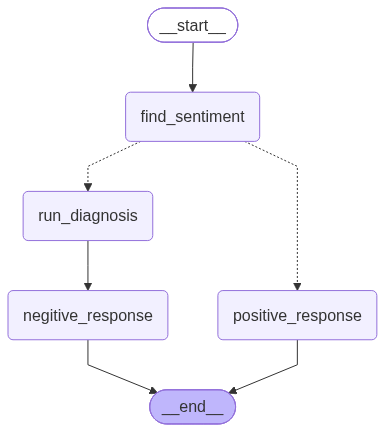

In [44]:
workflow

In [48]:
in_state={
    'review': "what is the fucking app its so much buh in there and too laggyy and stucking you fucking company solve this problem right now."
}

In [49]:
workflow.invoke(in_state)

{'review': 'what is the fucking app its so much buh in there and too laggyy and stucking you fucking company solve this problem right now.',
 'sentiment': 'negative',
 'diagnosis': {'issue_type': 'performance',
  'tone': 'angry',
  'urgency': 'high'},
 'response': AIMessage(content=[{'type': 'text', 'text': 'Subject: Urgent: Addressing your performance concerns regarding [Product/Service Name]\n\nDear [User Name],\n\nI want to sincerely apologize for the frustration you’ve experienced regarding the performance of [Product/Service Name]. I understand how critical this is for your workflow, and I completely hear your concerns about the impact this has had on your productivity. Please know that I have prioritized this issue as a high-urgency matter.\n\nI have escalated this case to our technical team for an immediate investigation. To help us identify the root cause as quickly as possible, could you please provide a few additional details?\n\n*   **When did you first notice the performanc